In [41]:
import pandas as pd
from sqlalchemy import text

from data_access.connection import engine


pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

query = text("""
    SELECT
        i.ID,
        i.Issue_Key,
        p.Project_Key,
        i.Title,
        i.Type,
        i.Priority,
        i.Status,
        i.Creation_Date,
        i.Resolution_Date,
        i.Story_Point,
        i.Resolution_Time_Minutes
    FROM Issue AS i
    LEFT JOIN Project AS p ON p.ID = i.Project_ID
    ORDER BY i.ID
    LIMIT 1000
""")

df = pd.read_sql_query(query, engine)

In [43]:
query = text("""
    SELECT
        i.ID,
        i.Issue_Key,
        p.Project_Key,
        i.Title,
        i.Type,
        i.Priority,
        i.Status,
        i.Creation_Date,
        i.Resolution_Date,
        i.Story_Point,
        i.Resolution_Time_Minutes
    FROM Issue AS i
    LEFT JOIN Project AS p ON p.ID = i.Project_ID
    WHERE i.Priority = ""
    ORDER BY i.ID
    LIMIT 1000
""")

df = pd.read_sql_query(query, engine)
df.sample(10)

,ID,Issue_Key,Project_Key,Title,Type,Priority,Status,Creation_Date,Resolution_Date,Story_Point,Resolution_Time_Minutes
484,41879,CLOV-834,CLOV,"""Filter clover reports by method complexity / statement coverage""",Suggestion,,Closed,2010-01-14 23:17:10,2019-08-13 07:54:07,NaN,5036136.0
402,41680,CLOV-1069,CLOV,"""Upgrade Intelij libraries for unit tests""",Suggestion,,Closed,2012-04-12 13:51:17,2012-04-25 09:34:36,NaN,18463.0
0,27400,ALOY-1728,ALOY,"""Alloy compiler failed using TabbedBar/ButtonBar with SDK 9.0.0""",Bug,,Open,2020-03-31 09:55:03,NaT,NaN,0.0
621,42198,CLOV-447,CLOV,"""MethodInfo's throws and params fields are quite often empty arrays, use flyweight to reduce siz...",Suggestion,,Closed,2009-03-02 11:22:00,2009-03-16 22:57:07,NaN,20855.0
394,41662,CLOV-1090,CLOV,"""Consistent statistics reporting in IDE and HTML reports for subpackages""",Suggestion,,Closed,2012-05-16 09:19:34,2019-08-13 07:54:05,3.0,3808714.0
560,42065,CLOV-605,CLOV,"""Less painful per-test coverage updates""",Suggestion,,Closed,2009-06-09 15:09:12,2010-03-15 15:19:31,NaN,401830.0
289,41434,CLOV-1364,CLOV,"""as a developer I'd like to use test optimization for spock-based tests""",Suggestion,,Closed,2013-09-02 11:51:42,2019-08-13 07:52:49,53.0,3126001.0
942,42704,CWD-5476,CWD,"""Make Delegated Directory Pruning plugin part of Crowd""",Suggestion,,In Progress,2019-10-14 15:14:50,NaT,NaN,0.0
971,42751,CWD-5421,CWD,"""Add support for """"Amazon Linux 2 AMI"""" on Crowd DC Quickstart AWS template""",Suggestion,,Gathering Interest,2019-07-03 20:21:15,NaT,NaN,0.0
717,42378,CLOV-232,CLOV,"""Back Button broken under some circumstances""",Suggestion,,Closed,2008-04-15 05:23:27,2014-09-03 14:05:16,NaN,3358601.0


In [32]:
df.sample(10)

,ID,Issue_Key,Project_Key,Title,Type,Priority,Status,Creation_Date,Resolution_Date,Story_Point,Resolution_Time_Minutes
979,1046,XD-2782,XD,"""PostgreSQL server.yml options ignored""",Bug,Major,Done,2015-03-05 08:36:04,2015-07-13 09:49:55,2.0,187213.0
164,229,XD-3604,XD,"""Container process id's still showing after shutting them down""",Story,Minor,To Do,2015-10-08 22:36:54,NaT,2.0,0.0
18,83,XD-3750,XD,"""Cant completely remove custom module after putting properties in /config/modules/job/xx/xx.prop...",Bug,Major,To Do,2016-02-29 10:00:19,NaT,1.0,0.0
359,426,XD-3407,XD,"""Document the process of resolving and adding JARs to Boot loader""",Story,Minor,To Do,2015-08-18 17:36:03,NaT,3.0,0.0
569,636,XD-3195,XD,"""Investigate Rabbit performance issues""",Story,Minor,To Do,2015-06-22 14:21:37,NaT,8.0,0.0
648,715,XD-3116,XD,"""Update redis.tar.gz bundled in distribution to be version 3.0.1""",Story,Minor,Done,2015-05-28 08:39:44,2015-06-08 14:41:00,3.0,16201.0
230,297,XD-3535,XD,"""Port Mail as s-c-s sink""",Story,Minor,Done,2015-09-28 23:35:50,2015-11-14 16:01:28,2.0,67285.0
216,283,XD-3549,XD,"""Port Splitter as s-c-s processor""",Story,Minor,Done,2015-09-28 23:45:14,2015-11-14 16:01:28,2.0,67276.0
390,457,XD-3376,XD,"""Port gemfire-server sink as s-c-s module""",Story,Minor,Done,2015-08-07 17:52:25,2015-10-12 20:24:11,2.0,95191.0
373,440,XD-3393,XD,"""Upgrade receptor-client to comply with latest Receptor APIs""",Story,Minor,Done,2015-08-14 08:03:31,2015-08-14 08:09:16,3.0,5.0


In [7]:
import pandas as pd
from sqlalchemy import text

from data_access.connection import engine

query = text("""
    SELECT
        COALESCE(Priority, 'Не указан') AS Priority,
        COUNT(*) AS Issue_Count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS Percentage
    FROM Issue
    GROUP BY Priority
    ORDER BY Issue_Count DESC
""")

priority_stats = pd.read_sql_query(query, engine)

priority_stats

,Priority,Issue_Count,Percentage
0,,124073,27.08
1,Low,65819,14.36
2,Major - P3,57146,12.47
3,Medium,56920,12.42
4,Minor,55819,12.18
5,Major,34212,7.47
6,High,24447,5.34
7,Critical,11341,2.47
8,Trivial,6617,1.44
9,Minor - P4,5947,1.30


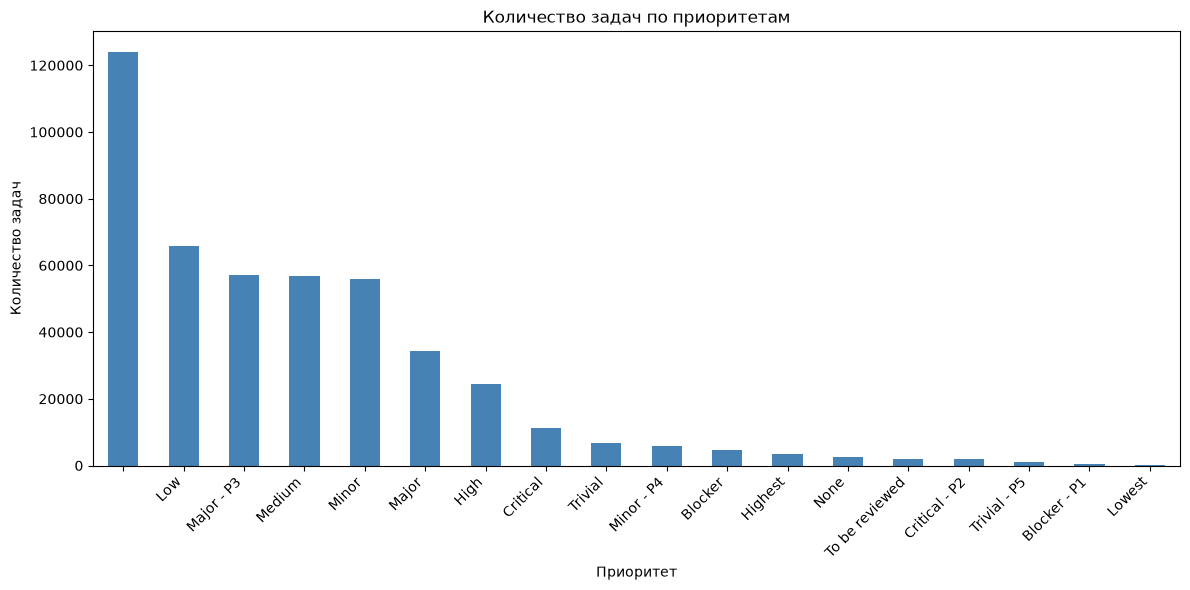

In [8]:
import matplotlib.pyplot as plt

ax = priority_stats.plot.bar(
    x="Priority",
    y="Issue_Count",
    figsize=(12, 6),
    legend=False,
    color="steelblue",
)

ax.set_title("Количество задач по приоритетам")
ax.set_xlabel("Приоритет")
ax.set_ylabel("Количество задач")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Note: you may need to restart the kernel to use updated packages.


D:\PROJECTS\average_task_performance\.venv\Scripts\python.exe: No module named uv
